# Bước 0 - Kiểm 20 cấu hình tinh chỉnh C1 (5 lõi x 2 độ sâu x 2 mức dung lượng) trên Kaggle T4: số tham số, tốc độ huấn luyện, thời gian một lượt validation 451 lưu vực, bộ nhớ GPU; ước tính giờ cho một lần chạy C1, C2 so với giới hạn 12 giờ/phiên của Kaggle. Không có lần chạy nào ở đây là kết quả chính thức của bước C.
# Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 5.2 (lưới C1, siêu tham số ngoài lưới), 6.5 (chi phí), 8.1 (ngân sách).
 Cấu hình nền: B1b (đại diện cho B*, chưa chọn); mốc tham số = LSTM của B1b (84.801).
# Cài đặt: Accelerator = GPU T4 x2 (dùng GPU 0), Internet = On, Persistence = Files only,
 Environment = Pin to original environment, Add Input => lamah-ce-ext và Output notebook 01_0_MambaSSM_Build
 (Version 1, wheel mamba-ssm, causal-conv1d). Mỗi Phần dán vào 1 cell, chạy lần lượt.

# MỤC LỤC
   Phần 1 - Cài fork nhánh research (fed53dc) và mamba-ssm, kiểm môi trường
   Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
   Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
   Phần 4 - Config B1b, khớp tham số 20 cấu hình C1
   Phần 5 - Dựng dataset train và validation một lần (data_on_gpu)
   Phần 6 - Đo thời gian 20 cấu hình: 200 bước huấn luyện, một lượt validation 451 lưu vực
   Phần 7 - Ước tính giờ một lần C1, C2 cho 20 cấu hình, so với giới hạn 12 giờ một phiên Kaggle
   Phần 8 - Tóm tắt, môi trường, danh mục tệp, dọn thư mục tạm

# Phần 1 - Cài fork nhánh research (fed53dc) và mamba-ssm, kiểm môi trường
 Cài fork theo mã commit (pip install git+...@commit, Pipeline Mục 9.1), cài wheel mamba-ssm theo cell Phần 9 của
 01_0_MambaSSM_Build. In 3 bảng (thư viện, môi trường, điều kiện); chưa đạt => raise.

In [1]:
# %% Phần 1 - Cài fork nhánh research (fed53dc) và mamba-ssm, kiểm môi trường
# Cài fork theo mã commit (pip install git+...@commit, Pipeline Mục 9.1), cài wheel mamba-ssm theo cell Phần 9 của
# 01_0_MambaSSM_Build. In 3 bảng (thư viện, môi trường, điều kiện); chưa đạt => raise.
import hashlib
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "fed53dca9815df963a5fa362558c448c769a6499"   # nhánh research = f229e02 (B0, B1a, B1b) + mô hình chung 5 lõi
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.nh_run", "neuralhydrology.evaluation.tester", "neuralhydrology.datautils.gpu_loader",
              "neuralhydrology.modelzoo.sequential_forecast", "neuralhydrology.modelzoo.sf_cores"]
TORCH_B0 = "2.11.0+cu128"                # torch của B0, B1a, B1b, 04_0 (ảnh Kaggle 10/2026); khác thì chỉ cảnh báo

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("cconf_work")
OUT_DIR = WORK_DIR / "cconf_output"      # bảng, hình, tóm tắt, môi trường
WHEEL_ROOTS = [Path("/kaggle/input"), WORK_DIR / "wheels"]
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    # số thực in 4 chữ số có nghĩa (mặc định Styler in 6 chữ số thập phân)
    display(df.style.hide(axis="index").format({c: "{:.4g}" for c in df.select_dtypes("float").columns}))


def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)


def installed_commit(dist):
    # Commit pip ghi lúc cài từ git (direct_url.json của bản cài), để chắc đúng phiên bản thư viện.
    text = md.distribution(dist).read_text("direct_url.json")
    return json.loads(text)["vcs_info"]["commit_id"] if text else None


def mamba_install():
    # Chép từ 01_0_MambaSSM_Build Phần 9: tìm build_info.json, kiểm Python/torch/CUDA khớp lúc dựng, sha256, cài --no-deps,
    # chạy thử một khối Mamba xuôi + ngược.
    import torch
    infos = [p for root in WHEEL_ROOTS if root.exists() for p in root.rglob("build_info.json")]
    if not infos:
        raise FileNotFoundError("Không thấy build_info.json: gắn Output của notebook 01_0_MambaSSM_Build làm Input")
    if len(infos) > 1:
        print("Thấy nhiều build_info.json, dùng tệp đầu tiên:", *infos, sep="\n  ")
    info_path = infos[0]
    info = json.loads(info_path.read_text())
    now = {"python": platform.python_version(), "torch": torch.__version__, "torch_cuda": torch.version.cuda}
    diff = {k: (info[k], v) for k, v in now.items() if info[k] != v}
    if diff:
        raise RuntimeError(f"Môi trường khác lúc dựng wheel (lúc dựng, bây giờ): {diff}. Phải dựng lại ở 01_0_MambaSSM_Build")
    gpu_cc = torch.cuda.get_device_capability(0) if torch.cuda.is_available() else None
    if gpu_cc != (7, 5):
        raise RuntimeError(f"Wheel chỉ có mã cho {info['arch']} (T4), GPU hiện tại: {gpu_cc}")
    wheels = []
    for name, digest in info["wheels"].items():
        whl = info_path.parent / name
        if hashlib.sha256(whl.read_bytes()).hexdigest() != digest:
            raise RuntimeError(f"sha256 của {name} không khớp build_info.json")
        wheels.append(str(whl))
    torch_dist = md.version("torch")  # bản đã cài trên đĩa (torch.__version__ không đổi khi pip cài lại)
    run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", *wheels])
    if md.version("torch") != torch_dist:
        raise RuntimeError("torch bị đổi sau khi cài wheel, khởi động lại phiên và kiểm lại lệnh cài")
    from mamba_ssm import Mamba
    m = Mamba(d_model=16).cuda()
    y = m(torch.randn(2, 8, 16, device="cuda", requires_grad=True))
    y.sum().backward()
    if not torch.isfinite(y).all():
        raise RuntimeError("Khối Mamba chạy thử ra NaN/inf")
    print(f"mamba-ssm đã cài từ {info_path.parent} (dựng {info['built_at']}, torch {info['torch']}, {info['arch']}); "
          f"chạy thử xuôi + ngược đạt")
    return info, info_path


# Cài fork theo commit (không editable: thư viện nằm trong site-packages như các notebook trước)
before = installed_versions(CHECK_LIBS)
run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"])
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
NH_INSTALLED_COMMIT = installed_commit("neuralhydrology")

MAMBA_BUILD_INFO, MAMBA_INFO_PATH = mamba_install()
mamba_versions = installed_versions(["mamba_ssm", "causal_conv1d"])

show("Thư viện (sau khi cài fork và mamba-ssm)", pd.DataFrame({
    "Thư viện": ["neuralhydrology", "mamba_ssm", "causal_conv1d"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {(NH_INSTALLED_COMMIT or 'không rõ')[:7]})",
                  mamba_versions["mamba_ssm"] or "THIẾU", mamba_versions["causal_conv1d"] or "THIẾU"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": ["", "", ""] + [f"từ {before[k]}" if before[k] != after[k] else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi cài để in đúng thiết bị

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "Số CPU": os.cpu_count(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
    "Wheel mamba-ssm": str(MAMBA_INFO_PATH.parent),
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng; sf_cores phải thấy mamba_ssm (MambaSSM khác None) thì lõi mamba mới dựng được
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

from neuralhydrology.modelzoo import sf_cores
from neuralhydrology.utils.config import Config

nh_path = Path(importlib.import_module("neuralhydrology").__file__).resolve()
checks = {
    "Cài đúng commit fed53dc": NH_INSTALLED_COMMIT == NH_COMMIT,
    "Nạp neuralhydrology từ site-packages": "site-packages" in str(nh_path) or "dist-packages" in str(nh_path),
    "pip không đổi thư viện có sẵn": not changed,
    "Có GPU T4 (dùng GPU 0)": n_gpu >= 1 and "T4" in gpus[0],
    "Có tensorboard": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
    "sf_cores thấy mamba_ssm": sf_cores.MambaSSM is not None,
    "Config có khóa sf_core, sf_dropout, sf_s4d_lr, data_on_gpu": all(
        isinstance(getattr(Config, k, None), property) for k in ["sf_core", "sf_dropout", "sf_s4d_lr", "data_on_gpu"]),
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")
print(f"neuralhydrology nạp từ: {nh_path.parent}")

if torch.__version__ != TORCH_B0:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của B0, B1a, B1b ({TORCH_B0}) - ảnh Kaggle đã đổi; ghi lại.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn:", ", ".join(f"{k} {before[k]} => {after[k]}" for k in changed))
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 2.")


mamba-ssm đã cài từ /kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels (dựng 2026-10-23T15:42:20+00:00, torch 2.11.0+cu128, sm_75); chạy thử xuôi + ngược đạt


Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit fed53dc),
mamba_ssm,2.3.2.post1,
causal_conv1d,1.6.2.post1,
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
Số CPU,4
RAM tổng / còn trống (GB),31.3 / 29.0
Đĩa trống ở WORK_DIR (GB),19.5
Ngày dựng ảnh Kaggle,20261022-041805
Wheel mamba-ssm,/kaggle/input/notebooks/hunhngcthng/01-0-mambassm-build/wheels


Điều kiện,Đạt
Cài đúng commit fed53dc,ĐẠT
Nạp neuralhydrology từ site-packages,ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có GPU T4 (dùng GPU 0),ĐẠT
Có tensorboard,ĐẠT
Nạp nh_run,ĐẠT
Nạp tester,ĐẠT
Nạp gpu_loader,ĐẠT
Nạp sequential_forecast,ĐẠT
Nạp sf_cores,ĐẠT


neuralhydrology nạp từ: /usr/local/lib/python3.13/dist-packages/neuralhydrology
=> Đạt. Chạy Phần 2.


# Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
 Chép nguyên B1b Phần 2 (đã chạy đạt ở 3 notebook B1b Version 1), chỉ đổi tên thư mục làm việc ở máy và cách
 show in số thực.
 Chỉ đọc, như B0 Phần 2: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản,
 kiểm đúng run bằng các siêu tham số, rồi xếp mọi khóa config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ.
 Khác B0: hindcast_inputs và dynamic_inputs cùng đổi ở Phần 4 (qmean => qmean_mmd, qmax_mmd tại cùng vị trí). dynamic_inputs là
 danh sách cột bộ nạp đọc vào bộ nhớ (basedataset.py dòng 350-353, 575-586); hindcast_inputs, forecast_inputs chỉ lấy lại
 từ các cột đó (dòng 172-176), thư viện không tự dựng dynamic_inputs (config.py dòng 360-362 ở f229e02) => phải đổi cả hai danh sách.
 Kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs. Tên cột mới phải nằm ngoài _VALID_TARGETS của
 bộ nạp (lamah.py dòng 18, 122-135): tên trong danh sách đó bị đọc lại từ D_gauges thay vì tệp khí tượng.
 Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.

In [2]:
# %% Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
# Chép nguyên B1b Phần 2 (đã chạy đạt ở 3 notebook B1b Version 1), chỉ đổi tên thư mục làm việc ở máy và cách
# show in số thực.
# Chỉ đọc, như B0 Phần 2: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản,
# kiểm đúng run bằng các siêu tham số, rồi xếp mọi khóa config vào 3 nhóm: giữ nguyên / đổi ở Phần 4 / bỏ.
# Khác B0: hindcast_inputs và dynamic_inputs cùng đổi ở Phần 4 (qmean => qmean_mmd, qmax_mmd tại cùng vị trí). dynamic_inputs là
# danh sách cột bộ nạp đọc vào bộ nhớ (basedataset.py dòng 350-353, 575-586); hindcast_inputs, forecast_inputs chỉ lấy lại
# từ các cột đó (dòng 172-176), thư viện không tự dựng dynamic_inputs (config.py dòng 360-362 ở f229e02) => phải đổi cả hai danh sách.
# Kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs. Tên cột mới phải nằm ngoài _VALID_TARGETS của
# bộ nạp (lamah.py dòng 18, 122-135): tên trong danh sách đó bị đọc lại từ D_gauges thay vì tệp khí tượng.
# Tự đủ: chạy lại được sau Restart mà không cần chạy lại Phần 1.
import os
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, display
from ruamel.yaml import YAML

from neuralhydrology.datasetzoo.lamah import _VALID_TARGETS

IS_KAGGLE = Path("/kaggle/working").exists()
SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("cconf_work")
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
Q_OLD = "qmean"                          # cột Q quá khứ của tác giả (m³/s)
Q_NEW = ["qmean_mmd", "qmax_mmd"]        # cột Q mm/ngày theo area_gov dựng ở Phần 3 (như B1a)
Q_USE = ["qmean_mmd", "qmax_mmd"]        # cột B1b đưa vào config thay Q_OLD (qmax_mmd ngay sau qmean_mmd)
# Giá trị phải có trong config tác giả (như B0 Phần 2) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa đổi ở Phần 4: 12 khóa của B0 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, hạt giống, tên run, giao thức
# 30 epoch, dữ liệu sẵn trên GPU) + 2 danh sách biến; khóa bỏ như B0
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file",
               "device", "num_workers", "verbose", "seed", "experiment_name", "early_stopping_patience", "data_on_gpu",
               "hindcast_inputs", "dynamic_inputs"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    # số thực in 4 chữ số có nghĩa (mặc định Styler in 6 chữ số thập phân)
    display(df.style.hide(axis="index").format({c: "{:.4g}" for c in df.select_dtypes("float").columns}))


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, tệp của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_RUN = EXP_DIR / AUTHOR_RUN_REL
AUTHOR_FILES = {"config": AUTHOR_RUN / "config.yml", "best_model.pt": AUTHOR_RUN / "best_model.pt",
                "scaler": AUTHOR_RUN / "train_data" / "train_data_scaler.yml",
                "test_metrics": AUTHOR_RUN / "test" / "best_model" / "test_metrics.csv"}
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau")]
    + [(f"Run tác giả: {k}", str(p.relative_to(EXP_DIR)), "có" if p.exists() else "THIẾU") for k, p in AUTHOR_FILES.items()],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not all(p.exists() for p in AUTHOR_FILES.values()):
    raise RuntimeError("Thiếu tệp của run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run, vị trí qmean, tên cột mới
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
hind = groups["hindcast_inputs"]
dyn = AUTHOR_CFG["dynamic_inputs"]
dyn_ok = dyn == hind + groups["forecast_inputs"]
all_inputs = dyn + hind + groups["forecast_inputs"] + groups["static_attributes"]
new_in_cfg = [c for c in Q_NEW if c in all_inputs]
new_in_targets = [c for c in Q_NEW if c.lower() in _VALID_TARGETS]
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": f"{Q_OLD} ở pha quá khứ, đúng 1 lần", "mong đợi": "1 lần", "trong config": f"{hind.count(Q_OLD)} lần",
              "khớp": "ĐẠT" if hind.count(Q_OLD) == 1 else "KHÔNG"},
             {"khóa": "dynamic_inputs = hindcast_inputs + forecast_inputs (đúng thứ tự)", "mong đợi": "trùng",
              "trong config": f"{len(dyn)} biến, " + ("trùng" if dyn_ok else "KHÁC"), "khớp": "ĐẠT" if dyn_ok else "KHÔNG"},
             {"khóa": f"{Q_OLD} không ở pha ngày t", "mong đợi": "không",
              "trong config": "có" if Q_OLD in groups["forecast_inputs"] else "không",
              "khớp": "ĐẠT" if Q_OLD not in groups["forecast_inputs"] else "KHÔNG"},
             {"khóa": "tên cột mới chưa có trong config", "mong đợi": "chưa có",
              "trong config": ", ".join(new_in_cfg) or "chưa có", "khớp": "ĐẠT" if not new_in_cfg else "KHÔNG"},
             {"khóa": "tên cột mới ngoài _VALID_TARGETS của bộ nạp", "mong đợi": f"ngoài {_VALID_TARGETS}",
              "trong config": ", ".join(new_in_targets) or "ngoài", "khớp": "ĐẠT" if not new_in_targets else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))
print(f"Biến quá khứ của tác giả ({len(hind)}), {Q_OLD} ở vị trí {hind.index(Q_OLD) + 1 if Q_OLD in hind else '-'}:")
print(", ".join(hind))

# (3) Mọi khóa config: giữ / đổi ở Phần 4 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 4" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 4": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 4')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

# (4) NSE test của tác giả (chỉ in để đối chiếu đúng run; notebook này không chấm test)
author_metrics = pd.read_csv(AUTHOR_FILES["test_metrics"], dtype={"basin": str}).set_index("basin")
AUTHOR_TEST_NSE_MEDIAN = float(author_metrics["NSE"].median())  # pandas bỏ NaN khi tính trung vị
show("NSE test của tác giả (test_metrics.csv)", pd.DataFrame([{
    "số lưu vực": len(author_metrics), "có NSE": int(author_metrics["NSE"].notna().sum()),
    "NaN": ", ".join(author_metrics.index[author_metrics["NSE"].isna()]) or "-",
    "NSE trung vị": round(AUTHOR_TEST_NSE_MEDIAN, 6), "KGE trung vị": round(float(author_metrics["KGE"].median()), 6),
    "khớp danh sách lưu vực": "ĐẠT" if set(author_metrics.index) == set(basins) else "KHÔNG"}]))

ok = all(r["khớp"] == "ĐẠT" for r in exp_rows) and set(author_metrics.index) == set(basins)
if not ok:
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")


mục,đường dẫn,ghi chú
Dữ liệu,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/lamah_ce_ext/LamaH_extended,
Kết quả tác giả,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments,
Danh sách lưu vực,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments/basins_filtered.txt,"451 lưu vực, 451 mã khác nhau"
Run tác giả: config,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/config.yml,có
Run tác giả: best_model.pt,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/best_model.pt,có
Run tác giả: scaler,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/train_data/train_data_scaler.yml,có
Run tác giả: test_metrics,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/test/best_model/test_metrics.csv,có


khóa,mong đợi,trong config,khớp
model,sequential_forecast_lstm,sequential_forecast_lstm,ĐẠT
seed,111,111,ĐẠT
hidden_size,128,128,ĐẠT
batch_size,256,256,ĐẠT
epochs,30,30,ĐẠT
learning_rate,0.001,0.001,ĐẠT
output_dropout,0.3,0.3,ĐẠT
seq_length,365,365,ĐẠT
forecast_seq_length,1,1,ĐẠT
early_stopping_patience,5,5,ĐẠT


Biến quá khứ của tác giả (32), qmean ở vị trí 32:
ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ERA5L_2m_dp_temp_max, ERA5L_2m_dp_temp_mean, ERA5L_2m_dp_temp_min, ERA5L_10m_wind_u, ERA5L_10m_wind_v, ERA5L_fcst_alb, ERA5L_lai_high_veg, ERA5L_lai_low_veg, ERA5L_swe, ERA5L_surf_net_solar_rad_max, ERA5L_surf_net_solar_rad_mean, ERA5L_surf_net_therm_rad_max, ERA5L_surf_net_therm_rad_mean, ERA5L_surf_press, ERA5L_total_et, ERA5L_prec, ERA5L_volsw_123, ERA5L_volsw_4, EOBS_tg, EOBS_tn, EOBS_tx, EOBS_rr, EOBS_pp, EOBS_fg, EOBS_qq, MSWEP_RR, GLEAM_ETA, GLEAM_ETP, qmean


khóa,giá trị tác giả,xử lý
data_dir,/home/ok2907/Documents/Data/LamaH_expanded_q_input,đổi ở Phần 4
data_on_gpu,"(không có, mặc định)",đổi ở Phần 4
device,cuda:0,đổi ở Phần 4
dynamic_inputs,"[37] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
early_stopping_patience,5,đổi ở Phần 4
experiment_name,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,đổi ở Phần 4
hindcast_inputs,"[32] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
num_workers,20,đổi ở Phần 4
run_dir,/home/ok2907/Documents/BiasCast/Experiments/Sequential_Forecast_LSTM/Sequential_Forecas...,đổi ở Phần 4
seed,111,đổi ở Phần 4


số lưu vực,có NSE,NaN,NSE trung vị,KGE trung vị,khớp danh sách lưu vực
451,450,55,0.7053,0.7671,ĐẠT


=> Đạt. Chạy Phần 3.


# Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
 Chép nguyên B1b Phần 3 (đã chạy đạt ở 3 notebook B1b Version 1); lamah.py, basedataset.py không đổi
 giữa f229e02 và fed53dc.
 Bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 116-119), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí
 tượng của 451 lưu vực, như B0 Phần 3 nhưng theo mm/ngày (mã B1 cũ, commit a06a224, đã chạy đạt; lamah.py, basedataset.py
 không đổi giữa dda45fc và f229e02). Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm -999 => NaN,
 lamah.py dòng 228-229) rồi _normalize_discharge với area_gov (dòng 303-308, cùng phép tính bộ nạp dùng cho nhãn qmax).
 Ghi 17 chữ số có nghĩa (đủ để float64 đọc lại đúng), ô thiếu để trống. Cột cũ chép nguyên từng ký tự; không thêm cột
 qmean m³/s. Thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có đủ 2 cột (Persistence) thì bỏ qua.
 Giống hệt B1a Phần 3 (đạt ở bản chạy tương tác B1a: 451 tệp, lệch 7.8e-14, ô trống trùng qmean m³/s). B1b đưa cả
 hai cột vào config (Phần 4).
 Kiểm: (1) đủ 451 tệp, area_gov dương; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực, đọc bằng
 load_lamah_forcing (đúng đường bộ nạp đọc đầu vào): qmax_mmd trùng nhãn qmax bộ nạp dựng, qmean_mmd trùng qmean D_gauges
 đổi đơn vị cùng cách (lệch tương đối <= 1e-12: pandas đọc lại số 17 chữ số có thể lệch bit cuối); ô trống qmean_mmd trùng ô trống qmean m³/s mà B0 dùng
 (=> cùng tập mẫu với B0); qmean_mmd, qmax_mmd cùng mặt nạ; không âm; qmax_mmd >= qmean_mmd; (4) thống kê trong khoảng
 tính chuẩn hóa (chỉ in, thư viện tự tính ở Phần 5).
 Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, Q_NEW, show).

In [3]:
# %% Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
# Chép nguyên B1b Phần 3 (đã chạy đạt ở 3 notebook B1b Version 1); lamah.py, basedataset.py không đổi
# giữa f229e02 và fed53dc.
# Bộ nạp chỉ đọc đầu vào từ tệp khí tượng (lamah.py dòng 116-119), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí
# tượng của 451 lưu vực, như B0 Phần 3 nhưng theo mm/ngày (mã B1 cũ, commit a06a224, đã chạy đạt; lamah.py, basedataset.py
# không đổi giữa dda45fc và f229e02). Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm -999 => NaN,
# lamah.py dòng 228-229) rồi _normalize_discharge với area_gov (dòng 303-308, cùng phép tính bộ nạp dùng cho nhãn qmax).
# Ghi 17 chữ số có nghĩa (đủ để float64 đọc lại đúng), ô thiếu để trống. Cột cũ chép nguyên từng ký tự; không thêm cột
# qmean m³/s. Thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có đủ 2 cột (Persistence) thì bỏ qua.
# Giống hệt B1a Phần 3 (đạt ở bản chạy tương tác B1a: 451 tệp, lệch 7.8e-14, ô trống trùng qmean m³/s). B1b đưa cả
# hai cột vào config (Phần 4).
# Kiểm: (1) đủ 451 tệp, area_gov dương; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực, đọc bằng
# load_lamah_forcing (đúng đường bộ nạp đọc đầu vào): qmax_mmd trùng nhãn qmax bộ nạp dựng, qmean_mmd trùng qmean D_gauges
# đổi đơn vị cùng cách (lệch tương đối <= 1e-12: pandas đọc lại số 17 chữ số có thể lệch bit cuối); ô trống qmean_mmd trùng ô trống qmean m³/s mà B0 dùng
# (=> cùng tập mẫu với B0); qmean_mmd, qmax_mmd cùng mặt nạ; không âm; qmax_mmd >= qmean_mmd; (4) thống kê trong khoảng
# tính chuẩn hóa (chỉ in, thư viện tự tính ở Phần 5).
# Cần chạy Phần 2 trước trong phiên (dùng LAMAH_DIR, WORK_DIR, basins, AUTHOR_FILES, Q_NEW, show).
import random
import time

from neuralhydrology.datasetzoo.lamah import (_normalize_discharge, load_lamah_attributes, load_lamah_discharge,
                                              load_lamah_forcing)
from neuralhydrology.utils.config import Config

Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
assert list(Q_SRC) == Q_NEW
N_CHECK = 3
LABEL_TOL = 1e-12  # lệch tương đối tối đa giữa cột ghi ra và giá trị tính lại (bản chạy tương tác đo được 7.8e-14)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_raw(data_dir, basin, src):
    # Q (m³/s) của D_gauges, -999 => NaN, đúng hàm bộ nạp gọi cho nhãn.
    return load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]


def q_mmd(data_dir, basin, src):
    # Q (m³/s) => mm/ngày theo area_gov, đúng phép tính bộ nạp dùng cho nhãn.
    return _normalize_discharge(ser=q_raw(data_dir, basin, src), area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


def rel_diff(a, b):
    # Lệch tương đối lớn nhất trên các ô cả hai có số, và số ô khác trạng thái trống.
    both = ~np.isnan(a) & ~np.isnan(b)
    rel = np.abs(a[both] - b[both]) / np.maximum(np.abs(b[both]), 1e-300)
    return (float(rel.max()) if rel.size else 0.0), int((np.isnan(a) != np.isnan(b)).sum())


# (1) Dựng thư mục
t0 = time.time()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]
area_ok = bool(np.isfinite(AREA.loc[basins]).all() and (AREA.loc[basins] > 0).all())
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
files = [Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv" for b in basins]
n_ok = sum(has_new_cols(f) for f in files)
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("area_gov của 451 lưu vực", f"{AREA.loc[basins].min():.1f} - {AREA.loc[basins].max():,.1f} km², "
                                 + ("đều dương" if area_ok else "CÓ GIÁ TRỊ KHÔNG HỢP LỆ")),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files if f.exists()) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian dựng", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, chỉ thêm đúng 2 cột
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    rows.append({"lưu vực": b, "số cột cũ / mới": f"{src.shape[1] - 1} / {new.shape[1] - 1}",
                 "cột thêm": ", ".join(c for c in new.columns if c not in src.columns),
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns=Q_NEW).equals(src) else "KHÔNG"})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (3) Cả 451 lưu vực, đọc lại bằng đường của bộ nạp, căn theo ngày của tệp khí tượng như _load_basin_data
#     (lamah.py dòng 107-135), từ ngày đầu khởi động kỳ train tới hết kỳ test
cfg_author = Config(AUTHOR_FILES["config"])
win_start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)
win_end = cfg_author.test_end_date
t1 = time.time()
area_q = load_lamah_attributes(Q_DIR, sub_dataset="lamah_a")["area_gov"]
assert area_q.loc[basins].equals(AREA.loc[basins]), "area_gov đọc từ thư mục Q khác bản gốc"
n_days = n_neg = n_order = n_mask_mm = n_nan_b0 = n_nan_label = n_nan_mean = 0
max_rel_label = max_rel_mean = 0.0
bad = {"qmax_mmd khác nhãn": [], "qmean_mmd khác qmean D_gauges": [], "ô trống qmean_mmd khác qmean m³/s": [],
       "mặt nạ qmean_mmd khác qmax_mmd": []}
norm_vals = {c: [] for c in Q_NEW}
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")
    w = df.loc[win_start:win_end]
    qm, qx = w["qmean_mmd"].to_numpy(), w["qmax_mmd"].to_numpy()
    label = q_mmd(Q_DIR, b, "qmax").reindex(df.index).loc[win_start:win_end].to_numpy()
    mean_ref = q_mmd(Q_DIR, b, "qmean").reindex(df.index).loc[win_start:win_end].to_numpy()
    mean_m3s = q_raw(Q_DIR, b, "qmean").reindex(df.index).loc[win_start:win_end].to_numpy()
    r_label, nan_label = rel_diff(qx, label)
    r_mean, nan_mean = rel_diff(qm, mean_ref)
    nan_b0 = int((np.isnan(qm) != np.isnan(mean_m3s)).sum())
    mask_mm = int((np.isnan(qm) != np.isnan(qx)).sum())
    n_days += len(w)
    max_rel_label, max_rel_mean = max(max_rel_label, r_label), max(max_rel_mean, r_mean)
    n_nan_label, n_nan_mean, n_nan_b0, n_mask_mm = n_nan_label + nan_label, n_nan_mean + nan_mean, n_nan_b0 + nan_b0, n_mask_mm + mask_mm
    n_neg += int((qm < 0).sum() + (qx < 0).sum())
    n_order += int((qx < qm).sum())
    for key, bad_b in [("qmax_mmd khác nhãn", r_label > LABEL_TOL or nan_label),
                       ("qmean_mmd khác qmean D_gauges", r_mean > LABEL_TOL or nan_mean),
                       ("ô trống qmean_mmd khác qmean m³/s", nan_b0), ("mặt nạ qmean_mmd khác qmax_mmd", mask_mm)]:
        if bad_b:
            bad[key].append(b)
    nw = df.loc[win_start:cfg_author.train_end_date]
    for c in Q_NEW:
        norm_vals[c].append(nw[c].to_numpy())
check_rows = [
    {"kiểm": "ngày-lưu vực đã kiểm", "kết quả": f"{n_days:,}", "đạt": ""},
    {"kiểm": "qmax_mmd so với nhãn qmax (lệch tương đối lớn nhất; ô trống khác)",
     "kết quả": f"{max_rel_label:.3g}; {n_nan_label:,}", "đạt": max_rel_label <= LABEL_TOL and n_nan_label == 0},
    {"kiểm": "qmean_mmd so với qmean D_gauges đổi đơn vị (lệch tương đối lớn nhất; ô trống khác)",
     "kết quả": f"{max_rel_mean:.3g}; {n_nan_mean:,}", "đạt": max_rel_mean <= LABEL_TOL and n_nan_mean == 0},
    {"kiểm": "ô trống qmean_mmd khác ô trống qmean m³/s của B0", "kết quả": f"{n_nan_b0:,}", "đạt": n_nan_b0 == 0},
    {"kiểm": "mặt nạ qmean_mmd khác qmax_mmd", "kết quả": f"{n_mask_mm:,}", "đạt": n_mask_mm == 0},
    {"kiểm": "giá trị âm", "kết quả": f"{n_neg:,}", "đạt": n_neg == 0},
    {"kiểm": "qmax_mmd < qmean_mmd", "kết quả": f"{n_order:,}", "đạt": n_order == 0}]
show(f"Kiểm cả {len(basins)} lưu vực, {win_start.date()} - {win_end.date()} ({time.time() - t1:.0f} giây)",
     pd.DataFrame(check_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG", "": ""})))
for name, ids in bad.items():
    if ids:
        print(f"Lưu vực {name}:", ", ".join(ids[:20]), "..." if len(ids) > 20 else "")

# (4) Thống kê trong khoảng tính chuẩn hóa (364 ngày khởi động + kỳ train, basedataset.py dòng 437-449); chỉ in
stat_rows = []
for c in Q_NEW:
    arr = np.concatenate(norm_vals[c])
    stat_rows.append({"cột": c, "trung bình (mm/ngày)": f"{np.nanmean(arr):.4f}", "độ lệch chuẩn": f"{np.nanstd(arr):.4f}",
                      "ô trống": f"{np.isnan(arr).sum():,} / {arr.size:,} ({np.isnan(arr).mean():.2%})"})
show(f"Thống kê {win_start.date()} - {cfg_author.train_end_date.date()}, {len(basins)} lưu vực", pd.DataFrame(stat_rows))

ok = (n_ok == len(basins) and area_ok and all(r["cột cũ giữ nguyên"] == "ĐẠT" for r in rows)
      and all(r["đạt"] is True for r in check_rows[1:]))
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")


mục,giá trị
Thư mục,/kaggle/working/LamaH_q_mmd_input
"Tệp khí tượng có qmean_mmd, qmax_mmd","451 / 451 (dựng mới 451, có sẵn 0)"
area_gov của 451 lưu vực,"3.9 - 15,131.0 km², đều dương"
Dung lượng,1.53 GB
Liên kết,"A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"
Thời gian dựng,313 giây


lưu vực,số cột cũ / mới,cột thêm,cột cũ giữ nguyên
788,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
330,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
698,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT


kiểm,kết quả,đạt
ngày-lưu vực đã kiểm,"2,635,193",
qmax_mmd so với nhãn qmax (lệch tương đối lớn nhất; ô trống khác),7.82e-14; 0,ĐẠT
qmean_mmd so với qmean D_gauges đổi đơn vị (lệch tương đối lớn nhất; ô trống khác),7.82e-14; 0,ĐẠT
ô trống qmean_mmd khác ô trống qmean m³/s của B0,0,ĐẠT
mặt nạ qmean_mmd khác qmax_mmd,0,ĐẠT
giá trị âm,0,ĐẠT
qmax_mmd < qmean_mmd,0,ĐẠT


cột,trung bình (mm/ngày),độ lệch chuẩn,ô trống
qmean_mmd,2.0872,3.5224,"51,291 / 1,317,371 (3.89%)"
qmax_mmd,2.6596,5.4931,"51,291 / 1,317,371 (3.89%)"


=> Đạt. Chạy Phần 4.


# Phần 4 - Config B1b, khớp tham số 20 cấu hình C1
 (1) Ghi config B1b hạt giống 111 đúng như B1b Phần 4 (14 khóa đổi, 5 khóa bỏ, qmean => qmean_mmd, qmax_mmd), nạp bằng
 Config, so từng khóa với config tác giả. B1b đại diện cho B* khi đo thời gian (mốc chính thức của C là LSTM của B*).
 (2) Mốc = số tham số của lõi LSTM 1 lớp trên config này, phải bằng SequentialForecastLSTM của B1b (84.801). Với 20 cấu
 hình C1 (Pipeline Mục 5.2: 5 lõi x 2 độ sâu x 2 mức dung lượng; learning rate không đổi số tham số, thời gian) gọi
 match_parameters của fork (sf_cores.py dòng 338-385 ở fed53dc), đếm bằng mô hình thật (Mamba dựng khối mamba_ssm thật),
 so với bảng Việc 1 tính ở máy (Mamba đếm bằng công thức): phải trùng từng số và lệch mốc <= 1%.
 Siêu tham số ngoài lưới theo Pipeline Mục 5.2: sf_dropout Transformer 0.1, S4D 0.1, Mamba 0 (lõi LSTM, GRU không dùng
 khóa này), sf_s4d_lr = min(0.001, learning_rate). Lưu bảng cho Phần 6.
 Cần chạy Phần 1-3 trước trong phiên (dùng sf_cores, AUTHOR_FILES, AUTHOR_CFG, KEYS_CHANGE, KEYS_DROP, BASIN_FILE, Q_DIR,
 Q_OLD, Q_USE, WORK_DIR, OUT_DIR, brief, show).

In [4]:
# %% Phần 4 - Config B1b, khớp tham số 20 cấu hình C1
# (1) Ghi config B1b hạt giống 111 đúng như B1b Phần 4 (14 khóa đổi, 5 khóa bỏ, qmean => qmean_mmd, qmax_mmd), nạp bằng
# Config, so từng khóa với config tác giả. B1b đại diện cho B* khi đo thời gian (mốc chính thức của C là LSTM của B*).
# (2) Mốc = số tham số của lõi LSTM 1 lớp trên config này, phải bằng SequentialForecastLSTM của B1b (84.801). Với 20 cấu
# hình C1 (Pipeline Mục 5.2: 5 lõi x 2 độ sâu x 2 mức dung lượng; learning rate không đổi số tham số, thời gian) gọi
# match_parameters của fork (sf_cores.py dòng 338-385 ở fed53dc), đếm bằng mô hình thật (Mamba dựng khối mamba_ssm thật),
# so với bảng Việc 1 tính ở máy (Mamba đếm bằng công thức): phải trùng từng số và lệch mốc <= 1%.
# Siêu tham số ngoài lưới theo Pipeline Mục 5.2: sf_dropout Transformer 0.1, S4D 0.1, Mamba 0 (lõi LSTM, GRU không dùng
# khóa này), sf_s4d_lr = min(0.001, learning_rate). Lưu bảng cho Phần 6.
# Cần chạy Phần 1-3 trước trong phiên (dùng sf_cores, AUTHOR_FILES, AUTHOR_CFG, KEYS_CHANGE, KEYS_DROP, BASIN_FILE, Q_DIR,
# Q_OLD, Q_USE, WORK_DIR, OUT_DIR, brief, show).
import copy

from neuralhydrology.modelzoo import get_model

RUN_SEED = 111
RUNS_DIR = WORK_DIR / "cconf_runs"      # train_dir của các lần đo ở Phần 5-6
CFG_DIR = WORK_DIR / "cconf_configs"
N_WORKERS = 2
PATIENCE = 30                           # như B1b
B1B_PARAMS = 84_801                     # SequentialForecastLSTM của B1b (B1b Phần 4)
PARAM_TOL = 0.01
LR = 0.001                              # learning rate tác giả; mức 5e-4 của lưới chỉ đổi bước cập nhật
CORES = {"lstm": [1, 2], "gru": [1, 2], "transformer": [1, 2], "s4d": [2, 4], "mamba": [2, 4]}
DROPOUT = {"lstm": 0.0, "gru": 0.0, "transformer": 0.1, "s4d": 0.1, "mamba": 0.0}
LEVELS = {"cùng tham số": 1, "gấp 3": 3}
# Bảng Việc 1 (Plans/11_C_Prep.md Mục 4): (lõi, độ sâu, mức) => (hidden_size, kích thước trong, số tham số)
VIEC1 = {("lstm", 1, 1): (128, None, 84_801), ("lstm", 1, 3): (235, None, 254_824),
         ("lstm", 2, 1): (77, None, 84_042), ("lstm", 2, 3): (139, None, 253_736),
         ("gru", 1, 1): (150, None, 84_679), ("gru", 1, 3): (274, None, 255_179),
         ("gru", 2, 1): (90, None, 84_439), ("gru", 2, 3): (162, None, 255_583),
         ("transformer", 1, 1): (80, 335, 84_864), ("transformer", 1, 3): (144, 565, 254_438),
         ("transformer", 2, 1): (56, 243, 84_759), ("transformer", 2, 3): (100, 416, 254_361),
         ("s4d", 2, 1): (111, None, 84_757), ("s4d", 2, 3): (216, None, 254_017),
         ("s4d", 4, 1): (72, None, 84_385), ("s4d", 4, 3): (146, None, 255_769),
         ("mamba", 2, 1): (72, 143, 84_975), ("mamba", 2, 3): (132, 264, 254_641),
         ("mamba", 4, 1): (49, 96, 84_525), ("mamba", 4, 3): (91, 183, 254_613)}
INNER_KEYS = ["sf_transformer_dim_feedforward", "sf_mamba_d_inner"]


def experiment_name(seed):
    return f"B1b_SeqLSTM_Q_seed{seed}"


def swap_q(inputs):
    # qmean => Q_USE tại cùng vị trí.
    i = inputs.index(Q_OLD)
    return inputs[:i] + Q_USE + inputs[i + 1:]


def write_config(seed):
    # Như B1b Phần 4: dựng lại từ config gốc của tác giả, đổi đúng các khóa KEYS_CHANGE, bỏ KEYS_DROP.
    yaml_rt = YAML()
    yaml_rt.width = 4096
    CFG_DIR.mkdir(parents=True, exist_ok=True)
    cfg = yaml_rt.load(AUTHOR_FILES["config"].read_text(encoding="utf-8"))
    new_vals = {"data_dir": str(Q_DIR), "run_dir": str(RUNS_DIR), "train_basin_file": str(BASIN_FILE),
                "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE), "device": "cuda:0",
                "num_workers": N_WORKERS, "verbose": 0, "seed": seed, "experiment_name": experiment_name(seed),
                "early_stopping_patience": PATIENCE, "data_on_gpu": True,
                "hindcast_inputs": swap_q(list(cfg["hindcast_inputs"])),
                "dynamic_inputs": swap_q(list(cfg["dynamic_inputs"]))}
    assert set(new_vals) == set(KEYS_CHANGE), "new_vals phải đúng các khóa KEYS_CHANGE của Phần 2"
    for k in KEYS_DROP:
        cfg.pop(k, None)
    for k, v in new_vals.items():
        cfg[k] = v
    path = CFG_DIR / f"{experiment_name(seed)}.yml"
    with open(path, "w", encoding="utf-8") as f:
        yaml_rt.dump(cfg, f)
    return path


def c1_update(core, depth, lr=LR):
    # Khóa của mô hình chung cho một cấu hình C1 (chưa có kích thước, match_parameters điền sau).
    update = {"model": "sequential_forecast", "sf_core": core, "sf_layers": depth, "sf_dropout": DROPOUT[core],
              "learning_rate": lr}
    if core == "s4d":
        update["sf_s4d_lr"] = min(0.001, lr)
    return update


CFG_PATH = write_config(RUN_SEED)

# (1) Nạp bằng Config, so từng khóa với config tác giả, kiểm danh sách biến
new = YAML(typ="safe").load(CFG_PATH.read_text(encoding="utf-8"))
cfg_b1b = Config(CFG_PATH)  # báo lỗi nếu có khóa lạ hoặc giá trị sai kiểu
diff_rows = []
for k in sorted(set(AUTHOR_CFG) | set(new)):
    a, b = AUTHOR_CFG.get(k, "(không có)"), new.get(k, "(bỏ)")
    if a != b:
        diff_rows.append({"khóa": k, "tác giả": brief(a, 60), "B1b": brief(b, 60),
                          "được phép": "ĐẠT" if k in KEYS_CHANGE + KEYS_DROP else "KHÔNG"})
show(f"Khóa khác config tác giả ({len(diff_rows)} khóa; seed tác giả là 111 nên không có dòng seed)", pd.DataFrame(diff_rows))
hind_new, dyn_new, fc = cfg_b1b.hindcast_inputs, cfg_b1b.dynamic_inputs, cfg_b1b.forecast_inputs
cfg_rows = [
    {"kiểm": "epochs / early_stopping_patience / data_on_gpu / seed",
     "giá trị": f"{cfg_b1b.epochs} / {cfg_b1b.early_stopping_patience} / {cfg_b1b.data_on_gpu} / {cfg_b1b.seed}",
     "đạt": [cfg_b1b.epochs, cfg_b1b.early_stopping_patience, cfg_b1b.data_on_gpu, cfg_b1b.seed] == [30, 30, True, RUN_SEED]},
    {"kiểm": "số biến quá khứ / ngày t / động (mong đợi 33 / 5 / 38)",
     "giá trị": f"{len(hind_new)} / {len(fc)} / {len(dyn_new)}",
     "đạt": [len(hind_new), len(fc), len(dyn_new)] == [33, 5, 38] and dyn_new == hind_new + fc},
    {"kiểm": f"{Q_OLD} => {', '.join(Q_USE)} tại cùng vị trí, không còn {Q_OLD}",
     "giá trị": ", ".join(f"{c} ở vị trí {hind_new.index(c) + 1}" for c in Q_USE if c in hind_new),
     "đạt": hind_new == swap_q(AUTHOR_CFG["hindcast_inputs"]) and Q_OLD not in dyn_new}]

# (2) Mốc và 20 cấu hình
cfg_base = copy.deepcopy(cfg_b1b)
cfg_base.update_config(c1_update("lstm", 1))
n_b1b = sf_cores.count_parameters(get_model(copy.deepcopy(cfg_b1b)))
TARGET = sf_cores.count_model_parameters(cfg_base)
cfg_rows.append({"kiểm": "tham số SequentialForecastLSTM B1b / lõi LSTM 1 lớp (mốc)", "giá trị": f"{n_b1b:,} / {TARGET:,}",
                 "đạt": n_b1b == TARGET == B1B_PARAMS})
show("Config B1b (đọc lại bằng Config)",
     pd.DataFrame(cfg_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG"})))

t0 = time.time()
conf_rows = []
for core, depths in CORES.items():
    for depth in depths:
        for level, mult in LEVELS.items():
            cfg_c = copy.deepcopy(cfg_base)
            update = c1_update(core, depth)
            cfg_c.update_config(update)
            size = sf_cores.match_parameters(cfg_c, mult * TARGET, tolerance=PARAM_TOL)
            n_params = sf_cores.count_model_parameters(cfg_c, size)
            inner = next((size[k] for k in INNER_KEYS if k in size), None)
            exp = VIEC1[(core, depth, mult)]
            conf_rows.append({"cấu hình": f"{core}_L{depth}_x{mult}", "lõi": core, "độ sâu": depth, "mức": level,
                              "hidden_size": size["hidden_size"], "kích thước trong": inner if inner else "-",
                              "số tham số": n_params, "mốc": mult * TARGET,
                              "lệch %": 100 * (n_params - mult * TARGET) / (mult * TARGET),
                              "Việc 1": f"{exp[0]} / {exp[1] or '-'} / {exp[2]:,}",
                              "trùng Việc 1": "ĐẠT" if (size["hidden_size"], inner, n_params) == exp else "KHÔNG",
                              "update": json.dumps({**update, **size})})
conf_df = pd.DataFrame(conf_rows)
show(f"20 cấu hình C1 (mốc {TARGET:,}, gấp 3 = {3 * TARGET:,}; lệch <= {PARAM_TOL:.0%}), dò trong {time.time() - t0:.0f} giây",
     conf_df.drop(columns="update").round({"lệch %": 3}))
conf_df.to_csv(OUT_DIR / "c1_configs.csv", index=False)
print("Thuộc tính khác của lõi giữ mặc định:", {k: getattr(cfg_base, k) for k in
      ["sf_transformer_nheads", "sf_s4d_d_state", "sf_mamba_d_state", "sf_mamba_d_conv", "output_dropout"]})

ok = (all(r["được phép"] == "ĐẠT" for r in diff_rows) and all(r["đạt"] for r in cfg_rows)
      and bool((conf_df["lệch %"].abs() <= 100 * PARAM_TOL).all()) and bool((conf_df["trùng Việc 1"] == "ĐẠT").all()))
if not ok:
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 5.")


khóa,tác giả,B1b,được phép
commit_hash,91af6a0,(bỏ),ĐẠT
data_dir,/home/ok2907/Documents/Data/LamaH_expanded_q_input,/kaggle/working/LamaH_q_mmd_input,ĐẠT
data_on_gpu,(không có),True,ĐẠT
dynamic_inputs,"[37] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...","[38] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...",ĐẠT
early_stopping_patience,5,30,ĐẠT
experiment_name,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,B1b_SeqLSTM_Q_seed111,ĐẠT
hindcast_inputs,"[32] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...","[33] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...",ĐẠT
img_log_dir,None,(bỏ),ĐẠT
num_workers,20,2,ĐẠT
number_of_basins,451,(bỏ),ĐẠT


kiểm,giá trị,đạt
epochs / early_stopping_patience / data_on_gpu / seed,30 / 30 / True / 111,ĐẠT
số biến quá khứ / ngày t / động (mong đợi 33 / 5 / 38),33 / 5 / 38,ĐẠT
"qmean => qmean_mmd, qmax_mmd tại cùng vị trí, không còn qmean","qmean_mmd ở vị trí 32, qmax_mmd ở vị trí 33",ĐẠT
tham số SequentialForecastLSTM B1b / lõi LSTM 1 lớp (mốc),"84,801 / 84,801",ĐẠT


cấu hình,lõi,độ sâu,mức,hidden_size,kích thước trong,số tham số,mốc,lệch %,Việc 1,trùng Việc 1
lstm_L1_x1,lstm,1,cùng tham số,128,-,84801,84801,0,"128 / - / 84,801",ĐẠT
lstm_L1_x3,lstm,1,gấp 3,235,-,254824,254403,0.165,"235 / - / 254,824",ĐẠT
lstm_L2_x1,lstm,2,cùng tham số,77,-,84042,84801,-0.895,"77 / - / 84,042",ĐẠT
lstm_L2_x3,lstm,2,gấp 3,139,-,253736,254403,-0.262,"139 / - / 253,736",ĐẠT
gru_L1_x1,gru,1,cùng tham số,150,-,84679,84801,-0.144,"150 / - / 84,679",ĐẠT
gru_L1_x3,gru,1,gấp 3,274,-,255179,254403,0.305,"274 / - / 255,179",ĐẠT
gru_L2_x1,gru,2,cùng tham số,90,-,84439,84801,-0.427,"90 / - / 84,439",ĐẠT
gru_L2_x3,gru,2,gấp 3,162,-,255583,254403,0.464,"162 / - / 255,583",ĐẠT
transformer_L1_x1,transformer,1,cùng tham số,80,335,84864,84801,0.074,"80 / 335 / 84,864",ĐẠT
transformer_L1_x3,transformer,1,gấp 3,144,565,254438,254403,0.014,"144 / 565 / 254,438",ĐẠT


Thuộc tính khác của lõi giữ mặc định: {'sf_transformer_nheads': 4, 'sf_s4d_d_state': 64, 'sf_mamba_d_state': 16, 'sf_mamba_d_conv': 4, 'output_dropout': 0.3}
=> Đạt. Chạy Phần 5.


# Phần 5 - Dựng dataset train và validation một lần (data_on_gpu)
 Dùng chung cho 20 cấu hình ở Phần 6 (dataset không phụ thuộc lõi). Train: get_dataset như BaseTrainer._get_dataset, lô
 lấy bằng GpuBatchLoader như _get_data_loader khi data_on_gpu (basetrainer.py dòng 83-84, 104-107 ở fed53dc); thư viện
 ghi tệp chuẩn hóa vào train_dir (basedataset.py dòng 254-262) để Tester đọc lại. Validation: Tester như
 BaseTrainer._get_tester (dòng 101-102), đủ 451 lưu vực như trainer đặt validate_n_random_basins (dòng 196-204); dựng
 cache 451 lưu vực trước như B0 Phần 6 (tester.py dòng 232-241) kèm bản trên GPU của từng lưu vực (dòng 165-171), nên
 Phần 6 chỉ đo thời gian chạy mô hình và tính chỉ số.
 Kiểm: số mẫu, số bước bằng B0 (1.094.272 mẫu, 4.275 bước - B1b Phần 4 Version 1); có tệp chuẩn hóa; đủ 451 lưu vực
 validation. Đo thời gian dựng (phần cố định của mỗi lần chạy C) và bộ nhớ GPU.
 Cần chạy Phần 1-4 trước trong phiên (dùng cfg_b1b, RUNS_DIR, basins, show).

In [5]:
# %% Phần 5 - Dựng dataset train và validation một lần (data_on_gpu)
# Dùng chung cho 20 cấu hình ở Phần 6 (dataset không phụ thuộc lõi). Train: get_dataset như BaseTrainer._get_dataset, lô
# lấy bằng GpuBatchLoader như _get_data_loader khi data_on_gpu (basetrainer.py dòng 83-84, 104-107 ở fed53dc); thư viện
# ghi tệp chuẩn hóa vào train_dir (basedataset.py dòng 254-262) để Tester đọc lại. Validation: Tester như
# BaseTrainer._get_tester (dòng 101-102), đủ 451 lưu vực như trainer đặt validate_n_random_basins (dòng 196-204); dựng
# cache 451 lưu vực trước như B0 Phần 6 (tester.py dòng 232-241) kèm bản trên GPU của từng lưu vực (dòng 165-171), nên
# Phần 6 chỉ đo thời gian chạy mô hình và tính chỉ số.
# Kiểm: số mẫu, số bước bằng B0 (1.094.272 mẫu, 4.275 bước - B1b Phần 4 Version 1); có tệp chuẩn hóa; đủ 451 lưu vực
# validation. Đo thời gian dựng (phần cố định của mỗi lần chạy C) và bộ nhớ GPU.
# Cần chạy Phần 1-4 trước trong phiên (dùng cfg_b1b, RUNS_DIR, basins, show).
from neuralhydrology.datasetzoo import get_dataset
from neuralhydrology.datautils.gpu_loader import GpuBatchLoader
from neuralhydrology.evaluation import get_tester
from neuralhydrology.utils.errors import NoEvaluationDataError

DEVICE = torch.device("cuda:0")
B0_SAMPLES, B0_STEPS = 1_094_272, 4_275
SHARED_RUN = RUNS_DIR / "shared"

shutil.rmtree(SHARED_RUN, ignore_errors=True)
cfg_run = copy.deepcopy(cfg_b1b)
cfg_run.update_config({"run_dir": str(SHARED_RUN), "train_dir": str(SHARED_RUN / "train_data"),
                       "validate_n_random_basins": len(basins)})
cfg_run.train_dir.mkdir(parents=True)

# (1) Train
t0 = time.time()
ds_train = get_dataset(cfg=cfg_run, is_train=True, period="train", scaler={})
loader = GpuBatchLoader(ds_train, batch_size=cfg_run.batch_size, device=DEVICE, shuffle=True)
torch.cuda.synchronize()
TRAIN_BUILD_MIN = (time.time() - t0) / 60
gpu_train_gb = torch.cuda.memory_allocated() / 1024 ** 3

# (2) Validation
t0 = time.time()
validator = get_tester(cfg=cfg_run, run_dir=SHARED_RUN, period="validation", init_model=False)
skipped = []
for b in validator.basins:
    try:
        validator.cached_datasets[b] = validator._get_dataset(b)
    except NoEvaluationDataError:
        skipped.append(b)
        continue
    validator._get_loader(validator.cached_datasets[b])  # bản trên GPU gắn vào dataset (tester.py dòng 165-171)
torch.cuda.synchronize()
VAL_BUILD_MIN = (time.time() - t0) / 60
gpu_all_gb = torch.cuda.memory_allocated() / 1024 ** 3

build_rows = [
    {"mục": "mẫu huấn luyện sau lọc", "giá trị": f"{len(ds_train):,}", "mong đợi": f"{B0_SAMPLES:,} (B0)",
     "đạt": len(ds_train) == B0_SAMPLES},
    {"mục": f"bước / epoch (lô {cfg_run.batch_size})", "giá trị": f"{len(loader):,}", "mong đợi": f"{B0_STEPS:,} (B0)",
     "đạt": len(loader) == B0_STEPS},
    {"mục": "tệp chuẩn hóa train_data_scaler.yml", "giá trị": "có" if (cfg_run.train_dir / "train_data_scaler.yml").exists()
     else "không", "mong đợi": "có", "đạt": (cfg_run.train_dir / "train_data_scaler.yml").exists()},
    {"mục": "lưu vực validation có dataset / bỏ qua", "giá trị": f"{len(validator.cached_datasets)} / {len(skipped)}",
     "mong đợi": f"{len(basins)} / 0", "đạt": len(validator.cached_datasets) == len(basins) and not skipped},
    {"mục": "kỳ validation", "giá trị": f"{cfg_run.validation_start_date.date()} - {cfg_run.validation_end_date.date()}",
     "mong đợi": "", "đạt": ""},
    {"mục": "thời gian dựng train / validation", "giá trị": f"{TRAIN_BUILD_MIN:.1f} / {VAL_BUILD_MIN:.1f} phút",
     "mong đợi": "", "đạt": ""},
    {"mục": "GPU đã cấp: sau dựng train / sau dựng validation", "giá trị": f"{gpu_train_gb:.2f} / {gpu_all_gb:.2f} GB",
     "mong đợi": "", "đạt": ""}]
show("Dataset dùng chung cho Phần 6",
     pd.DataFrame(build_rows).assign(đạt=lambda d: d["đạt"].map({True: "ĐẠT", False: "KHÔNG", "": ""})))
if skipped:
    print("Lưu vực validation bỏ qua:", skipped)

if not all(r["đạt"] for r in build_rows if r["đạt"] != ""):
    raise RuntimeError("Phần 5 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 6.")


The following basins had not enough valid target values to calculate a standard deviation: 324, 600, 623. NSE loss values for this basin will be NaN.


mục,giá trị,mong đợi,đạt
mẫu huấn luyện sau lọc,"1,094,272","1,094,272 (B0)",ĐẠT
bước / epoch (lô 256),"4,275","4,275 (B0)",ĐẠT
tệp chuẩn hóa train_data_scaler.yml,có,có,ĐẠT
lưu vực validation có dataset / bỏ qua,451 / 0,451 / 0,ĐẠT
kỳ validation,2010-01-01 - 2013-12-31,,
thời gian dựng train / validation,1.7 / 1.5 phút,,
GPU đã cấp: sau dựng train / sau dựng validation,0.22 / 0.35 GB,,


=> Đạt. Chạy Phần 6.


# Phần 6 - Đo thời gian 20 cấu hình: 200 bước huấn luyện, một lượt validation 451 lưu vực
 Mỗi cấu hình (bảng c1_configs.csv của Phần 4): đặt hạt giống như BaseTrainer._set_random_seeds, dựng mô hình,
 get_optimizer (S4D tách nhóm lr SSM), loss NSE, chạy N_STEPS bước đúng vòng _train_epoch (pre_model_hook, loss,
 zero_grad, backward, cắt gradient, step - như 04_0_Cores_Check Phần 6), đo từ bước N_WARMUP (bỏ khởi động nhân).
 Rồi một lượt validation đủ 451 lưu vực bằng Tester của Phần 5 (evaluate với model, tính NSE, KGE như trainer gọi mỗi epoch,
 basetrainer.py dòng 259-265 ở fed53dc; không ghi tệp). Ghi ms/bước, phút/epoch quy ra 4.275 bước, phút/lượt validation,
 GPU đỉnh khi huấn luyện và khi validation. NSE trung vị sau 200 bước chỉ để biết lượt validation chạy thật (không so
 sánh lõi). Lưu c1_timing.csv cho Phần 7. Khoảng 1 giờ.
 Cần chạy Phần 1-5 trước trong phiên (dùng conf_df, cfg_run, loader, validator, DEVICE, OUT_DIR, show).

In [6]:
# %% Phần 6 - Đo thời gian 20 cấu hình: 200 bước huấn luyện, một lượt validation 451 lưu vực
# Mỗi cấu hình (bảng c1_configs.csv của Phần 4): đặt hạt giống như BaseTrainer._set_random_seeds, dựng mô hình,
# get_optimizer (S4D tách nhóm lr SSM), loss NSE, chạy N_STEPS bước đúng vòng _train_epoch (pre_model_hook, loss,
# zero_grad, backward, cắt gradient, step - như 04_0_Cores_Check Phần 6), đo từ bước N_WARMUP (bỏ khởi động nhân).
# Rồi một lượt validation đủ 451 lưu vực bằng Tester của Phần 5 (evaluate với model, tính NSE, KGE như trainer gọi mỗi epoch,
# basetrainer.py dòng 259-265 ở fed53dc; không ghi tệp). Ghi ms/bước, phút/epoch quy ra 4.275 bước, phút/lượt validation,
# GPU đỉnh khi huấn luyện và khi validation. NSE trung vị sau 200 bước chỉ để biết lượt validation chạy thật (không so
# sánh lõi). Lưu c1_timing.csv cho Phần 7. Khoảng 1 giờ.
# Cần chạy Phần 1-5 trước trong phiên (dùng conf_df, cfg_run, loader, validator, DEVICE, OUT_DIR, show).
import gc
import random

from neuralhydrology.training import get_loss_obj, get_optimizer, get_regularization_obj

N_STEPS, N_WARMUP = 200, 20
STEPS_PER_EPOCH = len(loader)


def sync():
    torch.cuda.synchronize()


def measure(update):
    # Như BaseTrainer: hạt giống => mô hình => optimizer, loss => lặp loader; rồi một lượt validation.
    cfg = copy.deepcopy(cfg_run)
    cfg.update_config(update)
    random.seed(RUN_SEED)
    np.random.seed(RUN_SEED)
    torch.cuda.manual_seed(RUN_SEED)
    torch.manual_seed(RUN_SEED)
    model = get_model(cfg).to(DEVICE)
    optimizer = get_optimizer(model, cfg)
    loss_obj = get_loss_obj(cfg).to(DEVICE)
    loss_obj.set_regularization_terms(get_regularization_obj(cfg))
    torch.cuda.reset_peak_memory_stats()
    model.train()
    losses, t_start = [], None
    for i, data in enumerate(loader):
        if i >= N_STEPS:
            break
        if i == N_WARMUP:
            sync()
            t_start = time.time()
        data = model.pre_model_hook(data, is_train=True)
        loss, _ = loss_obj(model(data), data)
        optimizer.zero_grad()
        loss.backward()
        if cfg.clip_gradient_norm is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.clip_gradient_norm)
        optimizer.step()
        losses.append(loss.item())
    sync()
    if len(losses) < N_STEPS:
        raise RuntimeError(f"Loader chỉ có {len(losses)} lô, cần {N_STEPS}")
    ms_step = (time.time() - t_start) / (N_STEPS - N_WARMUP) * 1000
    peak_train = torch.cuda.max_memory_allocated() / 1024 ** 3
    torch.cuda.reset_peak_memory_stats()
    t1 = time.time()
    res = validator.evaluate(save_results=False, metrics=cfg.metrics, model=model)
    sync()
    val_min = (time.time() - t1) / 60
    peak_val = torch.cuda.max_memory_allocated() / 1024 ** 3
    nse = [r["1D"]["NSE"] for r in res.values() if "NSE" in r.get("1D", {})]
    out = {"ms/bước": ms_step, "phút/epoch huấn luyện": ms_step * STEPS_PER_EPOCH / 60000,
           "phút/lượt validation": val_min, "GPU đỉnh huấn luyện (GB)": peak_train,
           "GPU đỉnh validation (GB)": peak_val, "số tham số (mô hình)": sf_cores.count_parameters(model),
           "loss hữu hạn": bool(np.isfinite(losses).all()), "loss 20 bước đầu": float(np.mean(losses[:20])),
           "loss 20 bước cuối": float(np.mean(losses[-20:])), "lưu vực có NSE": int(np.isfinite(nse).sum()),
           "NSE trung vị sau 200 bước": float(np.nanmedian(nse)) if len(nse) else float("nan")}
    del model, optimizer, loss_obj, res
    gc.collect()
    torch.cuda.empty_cache()
    return out


t_all = time.time()
timing_rows = []
for _, row in conf_df.iterrows():
    t0 = time.time()
    m = measure(json.loads(row["update"]))
    timing_rows.append({"cấu hình": row["cấu hình"], "lõi": row["lõi"], "độ sâu": row["độ sâu"], "mức": row["mức"],
                        "hidden_size": row["hidden_size"], "kích thước trong": row["kích thước trong"],
                        "số tham số": row["số tham số"], **m})
    print(f"{row['cấu hình']:<18} {m['ms/bước']:7.1f} ms/bước, validation {m['phút/lượt validation']:5.2f} phút, "
          f"GPU {m['GPU đỉnh huấn luyện (GB)']:.2f} GB ({time.time() - t0:.0f} giây)")
timing_df = pd.DataFrame(timing_rows)
timing_df.to_csv(OUT_DIR / "c1_timing.csv", index=False)
show(f"Đo {len(timing_df)} cấu hình ({N_STEPS} bước, đo từ bước {N_WARMUP}, lô {cfg_run.batch_size}; "
     f"{(time.time() - t_all) / 60:.0f} phút)",
     timing_df.drop(columns=["loss hữu hạn"]).round(
         {"ms/bước": 1, "phút/epoch huấn luyện": 2, "phút/lượt validation": 2, "GPU đỉnh huấn luyện (GB)": 2,
          "GPU đỉnh validation (GB)": 2, "loss 20 bước đầu": 4, "loss 20 bước cuối": 4, "NSE trung vị sau 200 bước": 3}))

checks = {
    "Số tham số mô hình dựng trên GPU trùng Phần 4": bool((timing_df["số tham số (mô hình)"] == timing_df["số tham số"]).all()),
    "Loss hữu hạn ở mọi bước, mọi cấu hình": bool(timing_df["loss hữu hạn"].all()),
    "Loss giảm (20 bước cuối < 20 bước đầu) ở mọi cấu hình":
        bool((timing_df["loss 20 bước cuối"] < timing_df["loss 20 bước đầu"]).all()),
    "Validation chạy đủ: số lưu vực có NSE như nhau ở mọi cấu hình": timing_df["lưu vực có NSE"].nunique() == 1,
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
print("Số lưu vực có NSE:", sorted(timing_df["lưu vực có NSE"].unique()))
if not all(checks.values()):
    raise RuntimeError("Phần 6 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 7.")


Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


lstm_L1_x1            34.8 ms/bước, validation  0.82 phút, GPU 1.73 GB (59 giây)


Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


lstm_L1_x3            81.2 ms/bước, validation  1.32 phút, GPU 1.44 GB (97 giây)


Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


...

Basin 55 All simulated values are NaN, thus metrics will be NaN, too.


mamba_L4_x3          303.7 ms/bước, validation  4.42 phút, GPU 2.12 GB (328 giây)


cấu hình,lõi,độ sâu,mức,hidden_size,kích thước trong,số tham số,ms/bước,phút/epoch huấn luyện,phút/lượt validation,GPU đỉnh huấn luyện (GB),GPU đỉnh validation (GB),số tham số (mô hình),loss 20 bước đầu,loss 20 bước cuối,lưu vực có NSE,NSE trung vị sau 200 bước
lstm_L1_x1,lstm,1,cùng tham số,128,-,84801,34.8,2.48,0.82,1.73,1.45,84801,0.065,0.0277,450,0.204
lstm_L1_x3,lstm,1,gấp 3,235,-,254824,81.2,5.78,1.32,1.44,0.91,254824,0.0645,0.0275,450,0.241
lstm_L2_x1,lstm,2,cùng tham số,77,-,84042,36.5,2.6,0.71,1.39,1.05,84042,0.074,0.0345,450,0.004
lstm_L2_x3,lstm,2,gấp 3,139,-,253736,256.9,18.3,8.63,2.04,1.55,253736,0.0643,0.0388,450,0.02
gru_L1_x1,gru,1,cùng tham số,150,-,84679,66,4.71,1.82,1.75,1.36,84679,0.0467,0.0191,450,0.479
gru_L1_x3,gru,1,gấp 3,274,-,255179,88.6,6.31,1.39,1.7,0.92,255179,0.047,0.0171,450,0.552
gru_L2_x1,gru,2,cùng tham số,90,-,84439,38.2,2.72,0.78,1.56,1,84439,0.0391,0.0168,450,0.459
gru_L2_x3,gru,2,gấp 3,162,-,255583,275,19.59,9.65,2.31,1.45,255583,0.0542,0.016,450,0.499
transformer_L1_x1,transformer,1,cùng tham số,80,335,84864,81.3,5.79,1.84,1.11,1.72,84864,0.2238,0.0278,450,0.184
transformer_L1_x3,transformer,1,gấp 3,144,565,254438,137.2,9.78,2.64,1.64,1.85,254438,0.2479,0.0198,450,0.401


Điều kiện,Đạt
Số tham số mô hình dựng trên GPU trùng Phần 4,ĐẠT
"Loss hữu hạn ở mọi bước, mọi cấu hình",ĐẠT
Loss giảm (20 bước cuối < 20 bước đầu) ở mọi cấu hình,ĐẠT
Validation chạy đủ: số lưu vực có NSE như nhau ở mọi cấu hình,ĐẠT


Số lưu vực có NSE: [np.int64(450)]
=> Đạt. Chạy Phần 7.


# Phần 7 - Ước tính giờ một lần C1, C2 cho 20 cấu hình, so với giới hạn 12 giờ một phiên Kaggle
 Từ số đo Phần 5-6 (giao thức Pipeline Mục 5.1: 30 epoch, validation mỗi epoch; C2 thêm chấm test mọi epoch và
 best_model.pt như B0 Phần 6):
   C1 = dựng train + dựng validation + 30 x (phút/epoch huấn luyện + phút/lượt validation)
   C2 = C1 + dựng test + 31 x phút/lượt test
 Lượt test lấy bằng lượt validation vì hai kỳ cùng số ngày (kiểm ở dưới), dựng test lấy bằng dựng validation. Chưa
 tính cài thư viện, dựng thư mục Q (khoảng 5 phút, Phần 1-3) và ghi trọng số mỗi epoch => ước tính thấp hơn thực tế
 vài phút. Kiểm cách đo: cấu hình lstm_L1_x1 (trùng B1b) phải gần số đo B0 chạy thật (2,6-2,9 phút huấn luyện,
 0,8 phút validation mỗi epoch, library.md). Hình cột giờ từng cấu hình; lưu c1_estimates.csv.
 Cần chạy Phần 1-6 trước trong phiên (dùng timing_df, cfg_run, TRAIN_BUILD_MIN, VAL_BUILD_MIN, OUT_DIR, show).

cấu hình,lõi,độ sâu,mức,hidden_size,kích thước trong,số tham số,phút/epoch huấn luyện,phút/lượt validation,phút/epoch (huấn luyện + validation),C1 (giờ),C2 (giờ),C1 so với 12 giờ,C2 so với 12 giờ
lstm_L1_x1,lstm,1,cùng tham số,128,-,84801,2.48,0.82,3.3,1.71,2.15,,
lstm_L1_x3,lstm,1,gấp 3,235,-,254824,5.78,1.32,7.1,3.6,4.31,,
lstm_L2_x1,lstm,2,cùng tham số,77,-,84042,2.6,0.71,3.31,1.71,2.1,,
lstm_L2_x3,lstm,2,gấp 3,139,-,253736,18.3,8.63,26.93,13.52,18.01,VƯỢT 12 giờ,VƯỢT 12 giờ
gru_L1_x1,gru,1,cùng tham số,150,-,84679,4.71,1.82,6.53,3.32,4.28,,
gru_L1_x3,gru,1,gấp 3,274,-,255179,6.31,1.39,7.7,3.91,4.65,,
gru_L2_x1,gru,2,cùng tham số,90,-,84439,2.72,0.78,3.5,1.8,2.23,,
gru_L2_x3,gru,2,gấp 3,162,-,255583,19.59,9.65,29.24,14.67,19.69,VƯỢT 12 giờ,VƯỢT 12 giờ
transformer_L1_x1,transformer,1,cùng tham số,80,335,84864,5.79,1.84,7.63,3.87,4.84,,
transformer_L1_x3,transformer,1,gấp 3,144,565,254438,9.78,2.64,12.42,6.26,7.66,,


lõi,số lần chạy,tổng giờ,số lần vượt 12 giờ
lstm,7,39.4,2
gru,8,47.4,2
transformer,8,48.9,0
s4d,8,67.2,2
mamba,8,69.9,2


Tổng C1: 39 lần, 273 giờ GPU


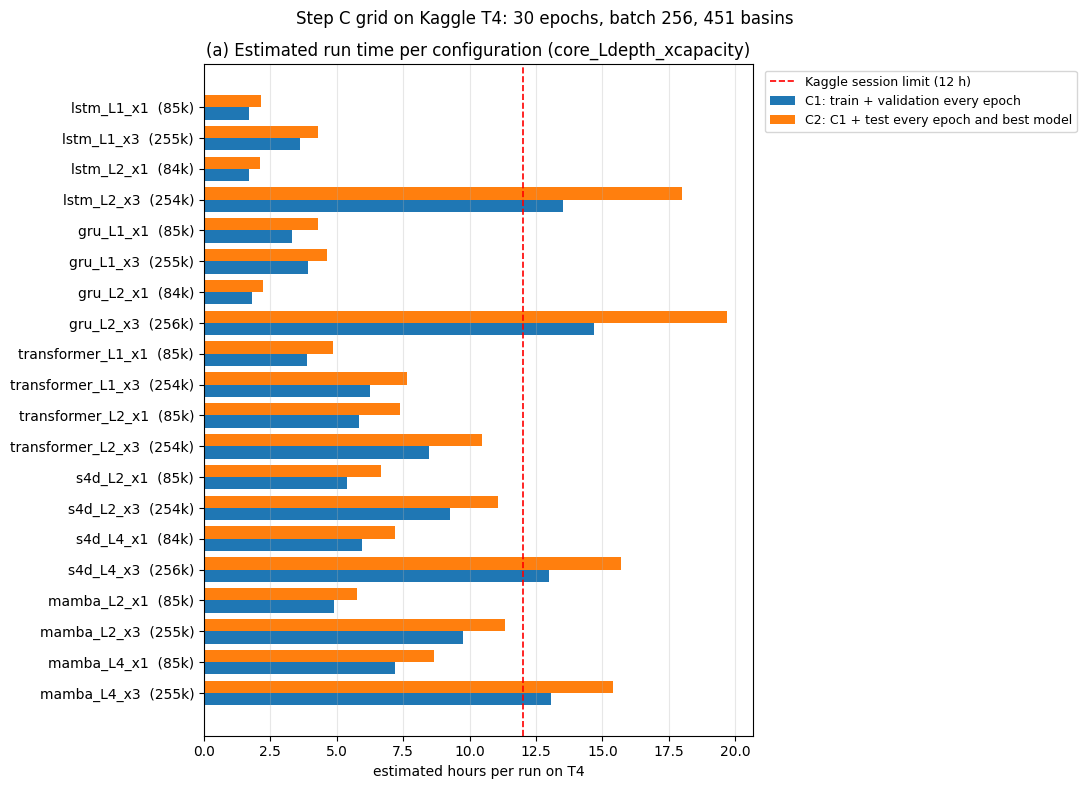

Hình: số giờ ước tính cho một lần chạy của từng cấu hình (tên: lõi_L<độ sâu>_x<mức dung lượng>, trong ngoặc là số tham số). Cột xanh là C1 (huấn luyện và validation mỗi epoch), cột cam là C2 (thêm chấm test mỗi epoch). Vạch đỏ là giới hạn 12 giờ một phiên Kaggle: C1 vượt ở 4 cấu hình (lstm_L2_x3, gru_L2_x3, s4d_L4_x3, mamba_L4_x3), C2 vượt ở 4 cấu hình. Cấu hình nhanh nhất lstm_L1_x1 (1,7 giờ C1), chậm nhất gru_L2_x3 (14,7 giờ C1).


Điều kiện,Đạt
Kỳ validation và test cùng số ngày (1461 / 1461),ĐẠT
lstm_L1_x1: huấn luyện 2.48 phút/epoch gần B0 2.6-2.9 (lệch <= 20%),ĐẠT
lstm_L1_x1: validation 0.82 phút/lượt gần B0 0.8 (lệch <= 20%),ĐẠT


=> Đạt. Chạy Phần 8.


In [7]:
# %% Phần 7 - Ước tính giờ một lần C1, C2 cho 20 cấu hình, so với giới hạn 12 giờ một phiên Kaggle
# Từ số đo Phần 5-6 (giao thức Pipeline Mục 5.1: 30 epoch, validation mỗi epoch; C2 thêm chấm test mọi epoch và
# best_model.pt như B0 Phần 6):
#   C1 = dựng train + dựng validation + 30 x (phút/epoch huấn luyện + phút/lượt validation)
#   C2 = C1 + dựng test + 31 x phút/lượt test
# Lượt test lấy bằng lượt validation vì hai kỳ cùng số ngày (kiểm ở dưới), dựng test lấy bằng dựng validation. Chưa
# tính cài thư viện, dựng thư mục Q (khoảng 5 phút, Phần 1-3) và ghi trọng số mỗi epoch => ước tính thấp hơn thực tế
# vài phút. Kiểm cách đo: cấu hình lstm_L1_x1 (trùng B1b) phải gần số đo B0 chạy thật (2,6-2,9 phút huấn luyện,
# 0,8 phút validation mỗi epoch, library.md). Hình cột giờ từng cấu hình; lưu c1_estimates.csv.
# Cần chạy Phần 1-6 trước trong phiên (dùng timing_df, cfg_run, TRAIN_BUILD_MIN, VAL_BUILD_MIN, OUT_DIR, show).
import matplotlib.pyplot as plt

LIMIT_H = 12                                   # giới hạn một phiên Kaggle
NEAR_H = 10                                    # dưới giới hạn nhưng sát (ghi chú)
B0_TRAIN_MIN, B0_VAL_MIN = (2.6, 2.9), 0.8     # B0 chạy thật, phút/epoch
REF_TOL = 0.2                                  # lệch tương đối tối đa so với B0
N_LR = 2                                       # số learning rate của lưới C1
FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def vn(x, digits=1):
    # Số thập phân trong chú thích tiếng Việt dùng dấu phẩy.
    return f"{x:.{digits}f}".replace(".", ",")


def n_days(start, end):
    return (end - start).days + 1


EPOCHS = cfg_run.epochs
days_val = n_days(cfg_run.validation_start_date, cfg_run.validation_end_date)
days_test = n_days(cfg_run.test_start_date, cfg_run.test_end_date)
est = timing_df[["cấu hình", "lõi", "độ sâu", "mức", "hidden_size", "kích thước trong", "số tham số",
                 "phút/epoch huấn luyện", "phút/lượt validation"]].copy()
est["phút/epoch (huấn luyện + validation)"] = est["phút/epoch huấn luyện"] + est["phút/lượt validation"]
est["C1 (giờ)"] = (TRAIN_BUILD_MIN + VAL_BUILD_MIN + EPOCHS * est["phút/epoch (huấn luyện + validation)"]) / 60
est["C2 (giờ)"] = est["C1 (giờ)"] + (VAL_BUILD_MIN + (EPOCHS + 1) * est["phút/lượt validation"]) / 60


def flag(h):
    return "VƯỢT 12 giờ" if h > LIMIT_H else (f"sát (> {NEAR_H} giờ)" if h > NEAR_H else "")


est["C1 so với 12 giờ"] = est["C1 (giờ)"].map(flag)
est["C2 so với 12 giờ"] = est["C2 (giờ)"].map(flag)
est.to_csv(OUT_DIR / "c1_estimates.csv", index=False)
show(f"Ước tính giờ một lần chạy ({EPOCHS} epoch; dựng train {TRAIN_BUILD_MIN:.1f} phút, dựng validation "
     f"{VAL_BUILD_MIN:.1f} phút)",
     est.round({"phút/epoch huấn luyện": 2, "phút/lượt validation": 2, "phút/epoch (huấn luyện + validation)": 2,
                "C1 (giờ)": 2, "C2 (giờ)": 2}))

# Tổng giờ C1 theo lõi: 2 learning rate x 4 cấu hình; cấu hình LSTM 1 lớp cùng tham số lr 1e-3 là B* (không chạy lại)
c1_total = est.groupby("lõi", sort=False)["C1 (giờ)"].sum() * N_LR
c1_total["lstm"] -= est.loc[est["cấu hình"] == "lstm_L1_x1", "C1 (giờ)"].iloc[0]
n_runs = est.groupby("lõi", sort=False).size() * N_LR
n_runs["lstm"] -= 1
show("Tổng giờ GPU của C1 theo lõi (chưa tính C2)", pd.DataFrame({
    "lõi": c1_total.index, "số lần chạy": n_runs.values, "tổng giờ": c1_total.values.round(1),
    "số lần vượt 12 giờ": [int((est.loc[est["lõi"] == c, "C1 (giờ)"] > LIMIT_H).sum() * N_LR) for c in c1_total.index]}))
print(f"Tổng C1: {int(n_runs.sum())} lần, {c1_total.sum():.0f} giờ GPU")

# Hình: giờ C1 và C2 từng cấu hình
fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(est))
ax.barh(y + 0.2, est["C1 (giờ)"], height=0.4, color="C0", label="C1: train + validation every epoch")
ax.barh(y - 0.2, est["C2 (giờ)"], height=0.4, color="C1", label="C2: C1 + test every epoch and best model")
ax.axvline(LIMIT_H, color="red", ls="--", lw=1.2, label=f"Kaggle session limit ({LIMIT_H} h)")
ax.set_yticks(y, [f"{c}  ({p / 1000:.0f}k)" for c, p in zip(est["cấu hình"], est["số tham số"])])
ax.invert_yaxis()
ax.set(xlabel="estimated hours per run on T4", title="(a) Estimated run time per configuration (core_Ldepth_xcapacity)")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
fig.suptitle(f"Step C grid on Kaggle T4: {EPOCHS} epochs, batch {cfg_run.batch_size}, {len(basins)} basins")
fig.tight_layout()
fig_path = FIG_DIR / "C0_Configs_Timing.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
over_c1 = est.loc[est["C1 (giờ)"] > LIMIT_H, "cấu hình"].tolist()
over_c2 = est.loc[est["C2 (giờ)"] > LIMIT_H, "cấu hình"].tolist()
caption(f"số giờ ước tính cho một lần chạy của từng cấu hình (tên: lõi_L<độ sâu>_x<mức dung lượng>, trong ngoặc là số "
        f"tham số). Cột xanh là C1 (huấn luyện và validation mỗi epoch), cột cam là C2 (thêm chấm test mỗi epoch). Vạch đỏ "
        f"là giới hạn {LIMIT_H} giờ một phiên Kaggle: C1 vượt ở {len(over_c1)} cấu hình ({', '.join(over_c1) or 'không có'}), "
        f"C2 vượt ở {len(over_c2)} cấu hình. Cấu hình nhanh nhất {est.loc[est['C1 (giờ)'].idxmin(), 'cấu hình']} "
        f"({vn(est['C1 (giờ)'].min())} giờ C1), chậm nhất {est.loc[est['C1 (giờ)'].idxmax(), 'cấu hình']} "
        f"({vn(est['C1 (giờ)'].max())} giờ C1).")

ref = est.loc[est["cấu hình"] == "lstm_L1_x1"].iloc[0]
checks = {
    f"Kỳ validation và test cùng số ngày ({days_val} / {days_test})": days_val == days_test,
    f"lstm_L1_x1: huấn luyện {ref['phút/epoch huấn luyện']:.2f} phút/epoch gần B0 {B0_TRAIN_MIN[0]}-{B0_TRAIN_MIN[1]} "
    f"(lệch <= {REF_TOL:.0%})":
        B0_TRAIN_MIN[0] * (1 - REF_TOL) <= ref["phút/epoch huấn luyện"] <= B0_TRAIN_MIN[1] * (1 + REF_TOL),
    f"lstm_L1_x1: validation {ref['phút/lượt validation']:.2f} phút/lượt gần B0 {B0_VAL_MIN} (lệch <= {REF_TOL:.0%})":
        abs(ref["phút/lượt validation"] - B0_VAL_MIN) <= REF_TOL * B0_VAL_MIN,
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
if not all(checks.values()):
    raise RuntimeError("Phần 7 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 8.")


# Phần 8 - Tóm tắt, môi trường, danh mục tệp, dọn thư mục tạm
 Output chính thức (cconf_output/): c1_configs.csv (Phần 4), c1_timing.csv (Phần 6), c1_estimates.csv và hình
 Figures/C0_Configs_Timing.png (Phần 7), config B1b dùng để đo, c_summary.json (số liệu chính), environment.json (Input,
 thư viện, commit), manifest.csv (sha256). Xóa thư mục dựng lại được: thư mục Q (1,5 GB), run dùng chung (dataset tạm,
 tệp chuẩn hóa), thư mục config. Cần Phần 1-7 trong phiên.

In [8]:
# %% Phần 8 - Tóm tắt, môi trường, danh mục tệp, dọn thư mục tạm
# Output chính thức (cconf_output/): c1_configs.csv (Phần 4), c1_timing.csv (Phần 6), c1_estimates.csv và hình
# Figures/C0_Configs_Timing.png (Phần 7), config B1b dùng để đo, c_summary.json (số liệu chính), environment.json (Input,
# thư viện, commit), manifest.csv (sha256). Xóa thư mục dựng lại được: thư mục Q (1,5 GB), run dùng chung (dataset tạm,
# tệp chuẩn hóa), thư mục config. Cần Phần 1-7 trong phiên.
ENV_LIBS = ["neuralhydrology", "mamba_ssm", "causal_conv1d", "torch", "numpy", "pandas", "xarray", "scipy", "numba",
            "ruamel.yaml", "matplotlib"]


def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def du_gb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file() and not f.is_symlink()) / 1e9


# (1) Tóm tắt
shutil.copy2(CFG_PATH, OUT_DIR / CFG_PATH.name)
SUMMARY = {
    "target_parameters": TARGET,
    "param_tolerance": PARAM_TOL,
    "configs": conf_df.drop(columns="update").to_dict("records"),
    "build_minutes": {"train": round(TRAIN_BUILD_MIN, 2), "validation": round(VAL_BUILD_MIN, 2)},
    "train_samples": len(ds_train), "steps_per_epoch": STEPS_PER_EPOCH,
    "timing": {"n_steps": N_STEPS, "n_warmup": N_WARMUP, "rows": timing_df.to_dict("records")},
    "estimates": {"epochs": EPOCHS, "limit_hours": LIMIT_H, "rows": est.to_dict("records"),
                  "c1_over_limit": over_c1, "c2_over_limit": over_c2,
                  "c1_total_hours": round(float(c1_total.sum()), 1), "c1_runs": int(n_runs.sum())},
}
(OUT_DIR / "c_summary.json").write_text(json.dumps(SUMMARY, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

# (2) Môi trường
env = {"python": sys.version.split()[0], "platform": platform.platform(),
       "gpu": torch.cuda.get_device_name(0), "cudnn": torch.backends.cudnn.version(),
       "neuralhydrology_commit": NH_INSTALLED_COMMIT, "neuralhydrology_commit_expected": NH_COMMIT,
       "neuralhydrology_branch": "research",
       "mamba_build": {k: MAMBA_BUILD_INFO.get(k) for k in ["built_at", "torch", "torch_cuda", "python", "arch"]},
       "inputs": {"lamah_dir": str(LAMAH_DIR), "author_run": str(AUTHOR_RUN), "mamba_wheels": str(MAMBA_INFO_PATH.parent)},
       "libs": installed_versions(ENV_LIBS), "kaggle_image": build_date,
       "q_dir_note": "LamaH_q_mmd_input dựng ở Phần 3 (như B1b: qmean_mmd, qmax_mmd theo area_gov), đã xóa khỏi Output"}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")

# (3) Dọn thư mục tạm (rmtree không đi theo liên kết tới dữ liệu gốc), danh mục tệp output
TMP_DIRS = [Q_DIR, RUNS_DIR, CFG_DIR]
for d in TMP_DIRS:
    if Path(d).exists():
        shutil.rmtree(d)
man = [{"tệp": p.relative_to(WORK_DIR).as_posix(), "KB": round(p.stat().st_size / 1e3, 1), "sha256": sha256_file(p)}
       for p in sorted(OUT_DIR.rglob("*")) if p.is_file() and p.name != "manifest.csv"]
MANIFEST = pd.DataFrame(man)
MANIFEST.to_csv(OUT_DIR / "manifest.csv", index=False)
show("Tệp Output (manifest.csv)", MANIFEST.assign(sha256=MANIFEST["sha256"].str[:12] + "..."))
sizes = [{"thư mục": d.name, "GB": round(du_gb(d), 3)} for d in sorted(WORK_DIR.iterdir()) if d.is_dir()]
show("Dung lượng /kaggle/working (Output của bản lưu)", pd.DataFrame(sizes))

OUT_FILES = ["c1_configs.csv", "c1_timing.csv", "c1_estimates.csv", "c_summary.json", "environment.json",
             "Figures/C0_Configs_Timing.png", CFG_PATH.name]
checks = {
    f"Commit thư viện đúng {NH_COMMIT[:7]}": NH_INSTALLED_COMMIT == NH_COMMIT,
    f"Đủ {len(OUT_FILES)} tệp output": all((OUT_DIR / f).exists() for f in OUT_FILES),
    "Đã xóa thư mục tạm": not any(Path(d).exists() for d in TMP_DIRS),
    "Tổng Output <= 1 GB": sum(r["GB"] for r in sizes) <= 1,
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
if not all(checks.values()):
    raise RuntimeError("Phần 8 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện)")
print("=> Đạt. Xong notebook.")


tệp,KB,sha256
cconf_output/B1b_SeqLSTM_Q_seed111.yml,3.6,0f01ce118006...
cconf_output/Figures/C0_Configs_Timing.png,150.8,c3a2ee32bb24...
cconf_output/c1_configs.csv,5.4,ae165b1b262a...
cconf_output/c1_estimates.csv,3.2,7b4fdd5c2302...
cconf_output/c1_timing.csv,4.6,ac16a9e6713a...
cconf_output/c_summary.json,35.3,ae9376223c78...
cconf_output/environment.json,1.4,db818d331fa8...


thư mục,GB
cconf_output,0


Điều kiện,Đạt
Commit thư viện đúng fed53dc,ĐẠT
Đủ 7 tệp output,ĐẠT
Đã xóa thư mục tạm,ĐẠT
Tổng Output <= 1 GB,ĐẠT


=> Đạt. Xong notebook.
